   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 4.0 MB/s eta 0:00:00


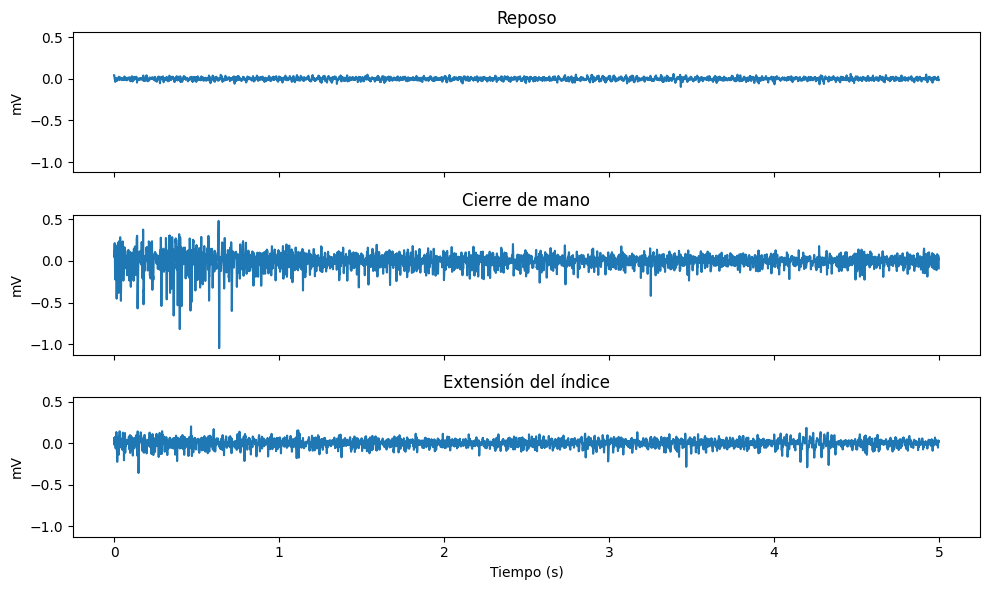

In [4]:
!pip install wfdb
import wfdb
import numpy as np
import matplotlib.pyplot as plt

carpeta = "grabmyo/1.1.0/Session1/session1_participant1"
gestos = {"Reposo": 17, "Cierre de mano": 16, "Extensión del índice": 9}
canal = 11  # canal F12 -> índice 11 en Python

senales = {}
for nombre_g, k in gestos.items():
    rec = wfdb.rdrecord(f"session1_participant1_gesture{k}_trial1", pn_dir=carpeta)
    senales[nombre_g] = rec.p_signal[:, canal]

fig, ax = plt.subplots(3, 1, sharex=True, sharey=True, figsize=(10, 6))
for a, (nombre_g, x) in zip(ax, senales.items()):
    a.plot(np.arange(len(x)) / rec.fs, x)
    a.set_title(nombre_g)
    a.set_ylabel("mV")
ax[-1].set_xlabel("Tiempo (s)")
plt.tight_layout()
plt.show()

Frecuencia de muestreo: 2048 Hz | Total de muestras: 30720


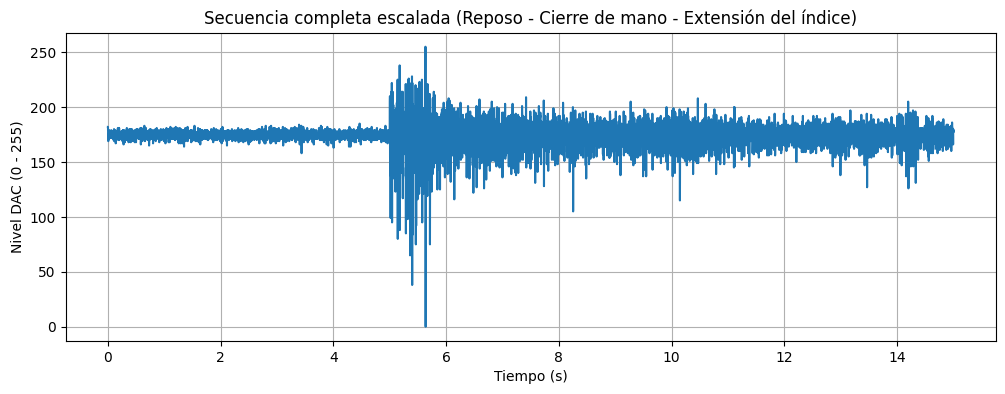

In [5]:
# Paso 4: Concatenar en el orden indicado: Reposo -> Cierre de mano -> Extensión del índice
secuencia = np.concatenate([
    senales["Reposo"],
    senales["Cierre de mano"],
    senales["Extensión del índice"]
])

# Verificar cantidad de muestras y frecuencia de muestreo
fs = int(rec.fs)          # Debe ser 2048 Hz
n_muestras = len(secuencia) # Debe ser 30720 muestras
print(f"Frecuencia de muestreo: {fs} Hz | Total de muestras: {n_muestras}")

# Paso 5: Escalado lineal único a valores enteros entre 0 y 255 (uint8)
min_val = np.min(secuencia)
max_val = np.max(secuencia)
secuencia_escalada = np.round((secuencia - min_val) / (max_val - min_val) * 255).astype(np.uint8)

# Paso 6: Graficar la secuencia escalada para verificar
tiempo_total = np.arange(n_muestras) / fs
plt.figure(figsize=(12, 4))
plt.plot(tiempo_total, secuencia_escalada)
plt.title("Secuencia completa escalada (Reposo - Cierre de mano - Extensión del índice)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Nivel DAC (0 - 255)")
plt.grid(True)
plt.show()

In [6]:
# Paso 7: Generar el archivo semg.h con el formato requerido
valores_str = ", ".join(map(str, secuencia_escalada))

contenido_h = f"""#ifndef SEMG_H
#define SEMG_H

#include <stdint.h>

const uint32_t N_SEMG = {n_muestras};
const uint16_t FS_SEMG = {fs};

const uint8_t SEMG[{n_muestras}] = {{
  {valores_str}
}};

#endif
"""

with open("semg.h", "w") as f:
    f.write(contenido_h)

# Descargar semg.h a la computadora (Anexo A.3)
from google.colab import files
files.download("semg.h")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

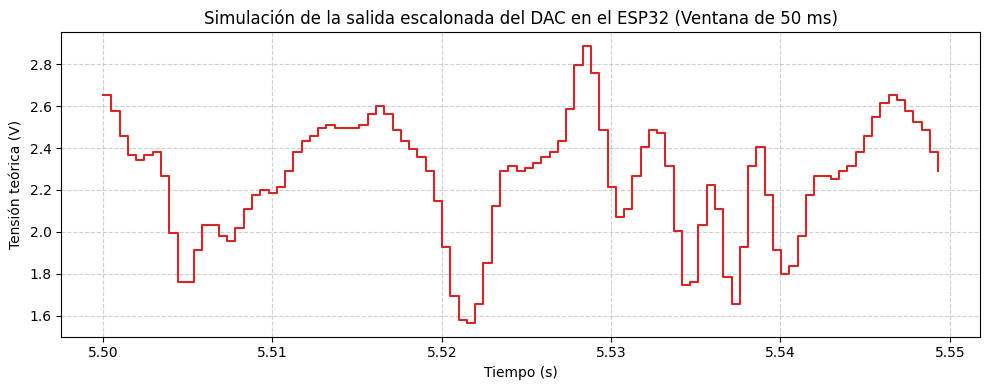

In [7]:
# Simulación de la salida del DAC a tensión (0 - 3.3V)
voltaje_dac = secuencia_escalada * (3.3 / 255.0)

# Extraer una ventana de 50 ms (aprox. 102 muestras) durante el cierre de mano (ej. t = 5.5 s)
inicio_idx = int(5.5 * fs)
fin_idx = inicio_idx + int(0.05 * fs)

t_ventana = tiempo_total[inicio_idx:fin_idx]
v_ventana = voltaje_dac[inicio_idx:fin_idx]

# Graficar usando representación escalonada
plt.figure(figsize=(10, 4))
plt.step(t_ventana, v_ventana, where='post', color='tab:red')
plt.title("Simulación de la salida escalonada del DAC en el ESP32 (Ventana de 50 ms)")
plt.xlabel("Tiempo (s)")
plt.ylabel("Tensión teórica (V)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()